# BERT and Job Categories - Solution

**Business problem:** suggest one of four categories for a publisher to review.

A model supports a decision; it does not make the business decision for us.

## Learning objectives

- Compare a text representation with frequency and TF-IDF baselines.
- Keep fitting, validation selection and final evaluation separate.
- Interpret errors and limits before proposing a business use.

## Dataset and practical scope

120 original synthetic German ads: 72 train, 24 validation, 24 test, ordered by constructed date. IDs and dates are not model features. Shared simple templates make this easier than a real job market. The measured results here do not reproduce the real-data slides.

All code is supplied. Run the cells from top to bottom.

## Libraries and settings

Use the prepared Python 3.11 Codespace kernel. No GPU or API key is needed.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)
DATA_ROOT = Path('../../../00_Data')

## 1. Minimal data inspection

Read the supplied CSV and retain its fixed chronological partitions.

In [1]:
jobs = pd.read_csv(DATA_ROOT / 'nlp_teaching_jobs.csv', parse_dates=['creation_date'])
parts = {name: jobs[jobs['split'] == name].copy()
         for name in ['train', 'validation', 'test']}
display(jobs[['text', 'category', 'split']].head(4))
display(jobs.groupby(['split', 'category']).size().unstack())

NameError: name 'pd' is not defined

## 2. Business and statistical baseline

A frequency baseline ignores text. TF-IDF plus logistic regression is a stronger lexical baseline. Fit vocabulary and IDF on training ads only.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train = parts['train']['category']
y_validation = parts['validation']['category']
y_test = parts['test']['category']
prior = DummyClassifier(strategy='prior').fit(np.zeros((len(y_train), 1)), y_train)
tfidf = TfidfVectorizer(ngram_range=(1, 2))
lexical = {name: tfidf.fit_transform(frame['text']) if name == 'train'
           else tfidf.transform(frame['text']) for name, frame in parts.items()}

## 3. Reuse a pretrained encoder

First use downloads public BERT files (about 700 MB). The text stays local. BERT's parameters remain fixed; no encoder is trained or fine-tuned on these ads. Download before the lecture. The supplied code reports input lengths and rebuilds TF-IDF on the same retained text: at most 126 content pieces plus two BERT markers.

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

torch.manual_seed(SEED)
torch.set_num_threads(2)
MODEL = 'google-bert/bert-base-multilingual-cased'
REVISION = '3f076fdb1ab68d5b2880cb87a0886f315b8146f8'
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=REVISION)
encoder = AutoModelForMaskedLM.from_pretrained(MODEL, revision=REVISION).eval()
for parameter in encoder.parameters():
    parameter.requires_grad_(False)
print('Frozen encoder; pooled values per document:', encoder.config.hidden_size)
lengths = [len(tokenizer(text)['input_ids']) for text in jobs['text']]
print('Longest input:', max(lengths), '| Inputs above the 128-token teaching cap:', sum(n > 128 for n in lengths))
retained = {name: tokenizer.batch_decode(
    tokenizer(frame['text'].tolist(), add_special_tokens=False, truncation=True, max_length=126)['input_ids'],
    clean_up_tokenization_spaces=False) for name, frame in parts.items()}
lexical = {name: tfidf.fit_transform(texts) if name == 'train' else tfidf.transform(texts)
           for name, texts in retained.items()}

/Users/iaracena/VisualStudioProjects/ZHAW/.venv-1/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'SEED' is not defined

## 4. Pool contextual token features

**Coding task:** multiply `hidden` by `content`, sum over token positions (`dim=1`), then divide by `content.sum(dim=1)`. The mask excludes padding and special markers. The output has 768 values, not four probabilities.

In [5]:
def encode_ads(texts):
    rows = []
    for start in range(0, len(texts), 8):
        batch = tokenizer(list(texts[start:start + 8]), padding=True, truncation=True,
                          max_length=128, return_tensors='pt', return_special_tokens_mask=True)
        special = batch.pop('special_tokens_mask')
        content = (batch['attention_mask'] * (1 - special)).unsqueeze(-1)
        with torch.inference_mode():
            hidden = encoder.base_model(**batch).last_hidden_state
            pooled = (hidden * content).sum(dim=1) / content.sum(dim=1)
        rows.append(pooled.numpy())
    return np.vstack(rows)

vectors = {name: encode_ads(frame['text'].tolist()) for name, frame in parts.items()}
print({name: matrix.shape for name, matrix in vectors.items()})

{'train': (72, 768), 'validation': (24, 768), 'test': (24, 768)}


### Interpret the result

Does frozen BERT produce identical outputs for different texts?

**Suggested answer:** No. Parameters stay fixed, but the representations depend on the input. A new category classifier learns from those features.

**Self-check:** Distinguish parameters, input-dependent features and the locally trained classifier.

**Difficulty:** moderate. A common mistake is treating a model score as business value.

## 5. Train and select the category classifier

**Coding task:** create `LogisticRegression(C=regularization, max_iter=600, random_state=SEED)`. The supplied loop compares C=0.3 and C=1 using validation macro-F1, giving each category equal weight. Choose the smaller C on a tie. Scaling is fitted on training vectors only.

In [6]:
representations = {'TF-IDF': lexical, 'Frozen BERT': vectors}
chosen = {}
validation_rows = []
for name, matrices in representations.items():
    candidates = []
    for regularization in [0.3, 1.0]:
        classifier = LogisticRegression(C=regularization, max_iter=600, random_state=SEED)
        model = (make_pipeline(StandardScaler(), classifier)
                 if name == 'Frozen BERT' else classifier)
        model.fit(matrices['train'], y_train)
        score = f1_score(y_validation, model.predict(matrices['validation']), average='macro')
        candidates.append((score, regularization, model))
        validation_rows.append({'model': name, 'C': regularization, 'validation macro-F1': score})
    candidates.sort(key=lambda item: (-item[0], item[1]))
    chosen[name] = candidates[0][2]
display(pd.DataFrame(validation_rows))

,model,C,validation macro-F1
0,TF-IDF,0.3,1.0
1,TF-IDF,1.0,1.0
2,Frozen BERT,0.3,1.0
3,Frozen BERT,1.0,1.0


## 6. Evaluate fixed choices

Do not change settings after seeing these test results. Accuracy counts correct first labels; macro-F1 weights categories equally.

In [7]:
test_predictions = {'Frequency': prior.predict(np.zeros((len(y_test), 1)))}
for name, model in chosen.items():
    test_predictions[name] = model.predict(representations[name]['test'])
results = [{'model': name,
            'accuracy': accuracy_score(y_test, prediction),
            'macro-F1': f1_score(y_test, prediction, average='macro')}
           for name, prediction in test_predictions.items()]
display(pd.DataFrame(results).set_index('model').round(3))

,accuracy,macro-F1
model,,
Frequency,0.25,0.1
TF-IDF,1.00,1.0
Frozen BERT,1.00,1.0


### Interpret the result

Which recipe would you investigate further? What prevents a deployment claim?

**Suggested answer:** In the saved run, TF-IDF and BERT both classify all test ads correctly. The cheaper lexical baseline therefore deserves consideration; a large encoder has not added value here. Shared synthetic templates make this unusually easy. Test real writing styles, rare labels, changes over time and publisher usefulness before deployment. Do not infer that TF-IDF always wins.

**Self-check:** Cite actual metrics, one failure mode and one business outcome to evaluate.

**Difficulty:** moderate. A common mistake is treating a model score as business value.

## Interpretation: inspect individual decisions

A confusion matrix and a few predictions help identify errors; do not interpret estimated category probabilities as calibrated truth.

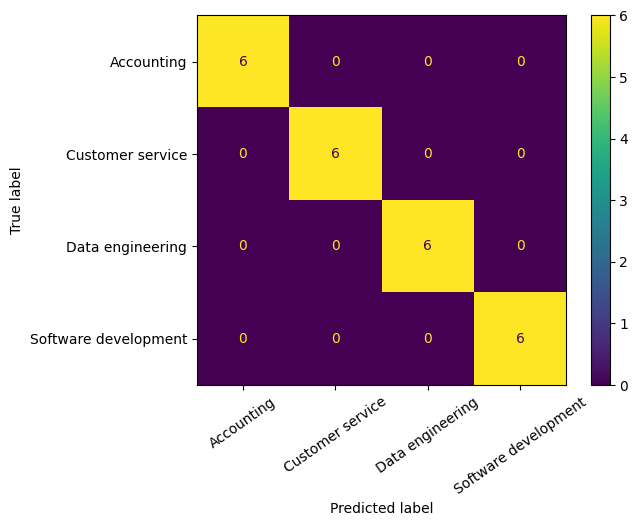

,text,category,predicted
96,Du bindest neue Datenquellen an. Du arbeitest ...,Data engineering,Data engineering
97,Du entwickelst Webanwendungen. Du arbeitest mi...,Software development,Software development
98,Du berätst unsere Kunden. Du arbeitest mit Ges...,Customer service,Customer service
99,Du bearbeitest Kreditoren und Debitoren. Du ar...,Accounting,Accounting
100,Du betreibst ETL-Prozesse. Du arbeitest mit Bi...,Data engineering,Data engineering
101,Du testest unsere Software. Du arbeitest mit C...,Software development,Software development


In [8]:
prediction = test_predictions['Frozen BERT']
ConfusionMatrixDisplay.from_predictions(y_test, prediction, xticks_rotation=35)
plt.show()
display(parts['test'][['text', 'category']].assign(predicted=prediction).head(6))

## Optional: a masked-token prediction

The output below is actual pretrained-model inference, not a training update or job-category prediction. The original text token, not the highest prediction, would be the MLM training target.

In [9]:
masked = tokenizer('We are hiring a [MASK] engineer.', return_tensors='pt')
position = int((masked['input_ids'][0] == tokenizer.mask_token_id).nonzero()[0].item())
with torch.inference_mode():
    probabilities = encoder(**masked).logits[0, position].softmax(dim=-1)
top = probabilities.topk(5)
display(pd.DataFrame({'token': tokenizer.convert_ids_to_tokens(top.indices.tolist()),
                      'model probability': top.values.tolist()}))

,token,model probability
0,civil,0.158858
1,tech,0.080237
2,qualified,0.069392
3,professional,0.062910
4,mechanical,0.027307


## Summary and business implications

Select with validation evidence, evaluate fixed recipes, then connect errors to publisher review. Changing representations is not a controlled causal experiment.

## Limitations

This is a small teaching example, not evidence of deployment performance. Keep evaluation separate from fitting and model selection. Check errors and the user's decision, not only a headline metric.

## Further exercises

- Inspect mistakes rather than only the mean score.
- What happens to unknown words or truncated requirements?
- Optional: use an authorized real dataset with a documented chronological split; do not redistribute private text.

## References

**Required reading:** BERT overview: https://huggingface.co/docs/transformers/model_doc/bert
**Instructor references:** Vaswani et al. (2017), *Attention Is All You Need*, https://arxiv.org/abs/1706.03762;
Devlin et al. (2019), *BERT*, https://aclanthology.org/N19-1423/;
Brown et al. (2020), *Language Models are Few-Shot Learners*, https://arxiv.org/abs/2005.14165.

### Jupyter notebook - footer info

Include your name, submission date and a short description of your changes when submitting.